# Cedar Trails: a ReAct hiking planner with configurable personas
**EECE 503P/798S Agentic Systems, Assignment: Agent Personas & Thinking Mechanisms**

Cedar Trails helps hikers plan sections of the **Lebanon Mountain Trail (LMT)**. It is a **ReAct agent built by hand in LangGraph**:
explicit `reason`, `act` and `finish` nodes with conditional edges, text-based `Thought / Action / Observation` steps, our own action
parser, and no prebuilt agent executor. Three personas share the loop but differ in **task, prompt traits and LLM configuration**.

| Section | Content |
|---|---|
| 1 | Use case: goal, audience, tools, constraints |
| 2-3 | Setup, data and tools (MCP-style schemas) |
| 4 | Personas: prompt traits + matching LLM configuration |
| 5 | Dedicated instructions block (with worked example) |
| 6-8 | LLM adapter, action parser, LangGraph ReAct loop |
| 9 | Live demo of the three personas |
| 10 | Experiments: personas x models, persona x config, prompt engineering, parameter sweeps |
| 11 | Reflection |
| 12 | Gradio app |

## 1. Use case

| | |
|---|---|
| **Agent goal** | Help people plan safe, enjoyable hikes on the Lebanon Mountain Trail: pick sections, estimate time, judge safety, and pack correctly. |
| **Target audience** | Local and diaspora hikers, from beginners planning a first day hike to fit groups attempting multi-day sections; also hiking clubs and guesthouse hosts. |
| **Tools** | `search_trail_sections`, `get_section_details`, `estimate_hike_time` (Naismith's rule), `get_season_conditions`, `check_safety_alerts`, `build_packing_list` |
| **Personas / tasks** | **Rami**, Friendly Trail Buddy: route inspiration. **Hala**, Strict Safety Ranger: go / no-go assessment. **Nour**, Gear Quartermaster: packing list. |
| **Constraints** | Answers must be grounded in tool observations (no invented sections or numbers); at most 5 tool calls per question; safety verdicts follow a fixed rule (danger alert, or high snow risk above 1500 m, means NO-GO). |
| **Limitations** | The trail data is a simplified, illustrative dataset (12 sections, typical seasonal conditions, simulated alerts), not live weather or official closures; time estimates use a rule of thumb; the agent cannot book guesthouses or guides. Real hikers must check lebanontrail.org and official advisories. |

## 2. Setup
Keys go in `.env` (never committed): `GROQ_API_KEY` (free, used for Qwen3.8-27B and GPT-OSS) and `GEMINI_API_KEY` (free tier).

In [1]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import ast
import json
import os
import re
import time
from datetime import datetime, timezone
from pathlib import Path
from typing import Optional, TypedDict

import requests
from dotenv import load_dotenv
from langgraph.graph import END, START, StateGraph

In [3]:
load_dotenv(override=True)

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:  # inside a notebook
    BASE_DIR = Path.cwd()

DATA = json.loads((BASE_DIR / "data" / "trail_data.json").read_text(encoding="utf-8"))
LOG_DIR = BASE_DIR / "logs"
LOG_DIR.mkdir(exist_ok=True)

GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")
GEMINI_MODEL = os.getenv("GEMINI_MODEL", "gemini-3.5-flash-lite")
OLLAMA_URL = os.getenv("OLLAMA_URL", "http://localhost:11434")
MAX_STEPS = 6  # maximum reason->act cycles per question

In [4]:
print(DATA["_note"])
print(len(DATA["sections"]), "sections:", ", ".join(s["id"] + " " + s["name"] for s in DATA["sections"][:4]), "...")

Illustrative, simplified data inspired by the Lebanon Mountain Trail (LMT) for an academic assignment. Distances, elevations, conditions and alerts are approximate or simulated. Always check lebanontrail.org and official advisories before hiking.
12 sections: S01 Andqet to Qbayat, S02 Qbayat to Akkar el Atika, S03 Sir ed-Danniyeh to Ehden, S04 Ehden to Bcharre (Kadisha rim) ...


## 3. Tools
Six deterministic Python tools. Each is documented MCP-style (`name`, `description`, `inputSchema`); the same descriptions are
rendered into the prompt (tool descriptions embedded in the instructions, as the assignment requires).

In [5]:
SECTIONS = {s["id"]: s for s in DATA["sections"]}
SEASON_OF_MONTH = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
                   6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}
MONTHS = ["january", "february", "march", "april", "may", "june", "july",
          "august", "september", "october", "november", "december"]


def _month(value):
    """Accept 7, "7", "July" or "jul" and return 1-12."""
    if isinstance(value, (int, float)) or str(value).strip().isdigit():
        month = int(value)
    else:
        text = str(value).strip().lower()[:3]
        month = next((i + 1 for i, m in enumerate(MONTHS) if m.startswith(text)), 0)
    if not 1 <= month <= 12:
        raise ValueError(f"unknown month: {value!r}")
    return month


def _section(section_id):
    section = SECTIONS.get(str(section_id).strip().upper())
    if section is None:
        raise ValueError(f"unknown section_id {section_id!r}; valid ids are S01 to S12")
    return section


def search_trail_sections(region="any", difficulty="any", max_distance_km=None, month=None):
    """Find trail sections matching optional filters."""
    matches = []
    for s in DATA["sections"]:
        if region != "any" and s["region"] != region:
            continue
        if difficulty != "any" and s["difficulty"] != difficulty:
            continue
        if max_distance_km is not None and s["distance_km"] > float(max_distance_km):
            continue
        if month is not None and _month(month) not in s["best_months"]:
            continue
        matches.append({k: s[k] for k in ("id", "name", "region", "difficulty", "distance_km", "elevation_gain_m", "highlights")})
    return {"count": len(matches), "sections": matches}


def get_section_details(section_id):
    """Full record for one section."""
    s = _section(section_id)
    return {**s, "best_months": [MONTHS[m - 1].title() for m in s["best_months"]]}


def estimate_hike_time(distance_km, elevation_gain_m, fitness="average"):
    """Naismith's rule: 5 km/h on the flat + 1 hour per 600 m of ascent, scaled by fitness."""
    factor = {"beginner": 1.3, "average": 1.0, "fit": 0.85}.get(str(fitness).lower())
    if factor is None:
        raise ValueError("fitness must be beginner, average or fit")
    moving = (float(distance_km) / 5 + float(elevation_gain_m) / 600) * factor
    return {
        "moving_hours": round(moving, 1),
        "total_hours_with_breaks": round(moving * 1.2, 1),
        "fitness_factor": factor,
        "method": "Naismith's rule (5 km/h + 1 h per 600 m ascent), +20% for breaks",
    }


def get_season_conditions(region, month):
    """Typical conditions for a region in a given month."""
    if region not in DATA["seasons"]:
        raise ValueError(f"region must be one of {list(DATA['seasons'])}")
    m = _month(month)
    season = SEASON_OF_MONTH[m]
    c = DATA["seasons"][region][season]
    return {"region": region, "month": MONTHS[m - 1].title(), "season": season,
            "temp_range_c": c["temp_c"], "snow_risk": c["snow_risk"], "daylight_hours": c["daylight_h"]}


def check_safety_alerts(section_id):
    """Simulated safety alerts for a section."""
    s = _section(section_id)
    alerts = DATA["alerts"].get(s["id"], [])
    worst = max((a["level"] for a in alerts), key=["info", "warning", "danger"].index, default="none")
    return {"section_id": s["id"], "highest_level": worst, "alerts": alerts}


def build_packing_list(days, month, overnight=False):
    """Packing list for a hike, adapted to season and duration."""
    days, season = max(1, int(days)), SEASON_OF_MONTH[_month(month)]
    essentials = ["map + offline GPS track", "first-aid kit", "headlamp", "sun hat + sunscreen",
                  "rain shell", "trail snacks", "water bottles or bladder", "phone + power bank", "whistle"]
    extras = {
        "winter": ["insulated jacket", "gloves + beanie", "microspikes or crampons", "gaiters", "thermos"],
        "spring": ["warm mid-layer", "light gloves", "gaiters for muddy trails"],
        "summer": ["electrolyte tablets", "lightweight long sleeves", "extra water capacity"],
        "autumn": ["warm mid-layer", "light gloves", "extra daylight margin (headlamp batteries)"],
    }[season]
    overnight_items = ["guesthouse booking confirmation", "sleep layer", "toiletries", "spare socks"] if overnight or days > 1 else []
    water = 3.5 if season == "summer" else 2.5
    weight = 6 + 1.2 * (days - 1) + (2 if season == "winter" else 0)
    return {"days": days, "season": season, "essentials": essentials, "season_extras": extras,
            "overnight": overnight_items, "water_liters_per_day": water, "estimated_pack_kg": round(weight, 1)}


# MCP-style tool definitions: name, description, inputSchema (+ the callable).
TOOLS = {
    "search_trail_sections": {
        "fn": search_trail_sections,
        "description": "Find LMT sections by region, difficulty, maximum distance and/or a month in their best season.",
        "inputSchema": {"type": "object", "properties": {
            "region": {"type": "string", "enum": ["any", "north", "mount_lebanon", "shouf", "south"]},
            "difficulty": {"type": "string", "enum": ["any", "easy", "moderate", "hard"]},
            "max_distance_km": {"type": "number"},
            "month": {"type": "string", "description": "Month name or number"}}},
    },
    "get_section_details": {
        "fn": get_section_details,
        "description": "Full stats for one section: distance, elevation, best months, water points, guesthouse.",
        "inputSchema": {"type": "object", "properties": {"section_id": {"type": "string", "description": "S01 to S12"}},
                        "required": ["section_id"]},
    },
    "estimate_hike_time": {
        "fn": estimate_hike_time,
        "description": "Estimate hiking hours from distance and elevation gain (Naismith's rule) for a fitness level.",
        "inputSchema": {"type": "object", "properties": {
            "distance_km": {"type": "number"}, "elevation_gain_m": {"type": "number"},
            "fitness": {"type": "string", "enum": ["beginner", "average", "fit"]}},
            "required": ["distance_km", "elevation_gain_m"]},
    },
    "get_season_conditions": {
        "fn": get_season_conditions,
        "description": "Typical temperature range, snow risk and daylight for a region in a month.",
        "inputSchema": {"type": "object", "properties": {
            "region": {"type": "string", "enum": ["north", "mount_lebanon", "shouf", "south"]},
            "month": {"type": "string"}}, "required": ["region", "month"]},
    },
    "check_safety_alerts": {
        "fn": check_safety_alerts,
        "description": "Current (simulated) safety alerts and closures for a section.",
        "inputSchema": {"type": "object", "properties": {"section_id": {"type": "string"}}, "required": ["section_id"]},
    },
    "build_packing_list": {
        "fn": build_packing_list,
        "description": "Season-aware packing list with water per day and estimated pack weight.",
        "inputSchema": {"type": "object", "properties": {
            "days": {"type": "integer"}, "month": {"type": "string"}, "overnight": {"type": "boolean"}},
            "required": ["days", "month"]},
    },
}


def describe_tools():
    """Tool descriptions embedded in the prompt."""
    lines = []
    for name, t in TOOLS.items():
        props = t["inputSchema"]["properties"]
        required = set(t["inputSchema"].get("required", []))
        args = ", ".join(f"{p}{'' if p in required else '?'}: {spec['type']}"
                         + (f" ({'|'.join(spec['enum'])})" if "enum" in spec else "") for p, spec in props.items())
        lines.append(f"- {name}({args}): {t['description']}")
    return "\n".join(lines)


def execute_tool(name, args):
    """Run a tool and return its observation (errors are returned, not raised)."""
    tool = TOOLS.get(name)
    if tool is None:
        return {"error": f"unknown tool {name!r}. Available: {', '.join(TOOLS)}"}
    allowed = tool["inputSchema"]["properties"]
    try:
        return tool["fn"](**{k: v for k, v in args.items() if k in allowed})
    except (TypeError, ValueError) as exc:
        return {"error": str(exc)}

In [6]:
print(describe_tools())
print(json.dumps(estimate_hike_time(11, 400, "beginner"), indent=1))
print(execute_tool("get_section_details", {"section_id": "S99"}))  # errors become observations

- search_trail_sections(region?: string (any|north|mount_lebanon|shouf|south), difficulty?: string (any|easy|moderate|hard), max_distance_km?: number, month?: string): Find LMT sections by region, difficulty, maximum distance and/or a month in their best season.
- get_section_details(section_id: string): Full stats for one section: distance, elevation, best months, water points, guesthouse.
- estimate_hike_time(distance_km: number, elevation_gain_m: number, fitness?: string (beginner|average|fit)): Estimate hiking hours from distance and elevation gain (Naismith's rule) for a fitness level.
- get_season_conditions(region: string (north|mount_lebanon|shouf|south), month: string): Typical temperature range, snow risk and daylight for a region in a month.
- check_safety_alerts(section_id: string): Current (simulated) safety alerts and closures for a section.
- build_packing_list(days: integer, month: string, overnight?: boolean): Season-aware packing list with water per day and estimated 

## 4. Personas: prompt traits + matching LLM configuration
Each persona is defined by **prompt wording** (tone, vocabulary, response style, values) **and** an **LLM configuration chosen to support it**:

| Persona | Task | Prompt traits | Config | Why this config fits |
|---|---|---|---|---|
| **Rami**, Friendly Trail Buddy | Route inspiration | warm, vivid, conversational, encouraging | temp 0.8, top_p 0.95, top_k 64, presence 0.4, 700 tokens | variety and fresh wording for inspiration |
| **Hala**, Strict Safety Ranger | Go / no-go | firm, precise, technical, verdict first | temp 0.1, top_p 0.5, top_k 10, no penalties, 450 tokens | the same facts should always give the same verdict; repetition of exact terms is good |
| **Nour**, Gear Quartermaster | Packing list | practical, concrete quantities, dry humour | temp 0.3, top_p 0.8, top_k 40, frequency 0.5, 600 tokens | consistent lists; frequency penalty discourages duplicate items |

In [7]:
# Each persona = prompt traits (tone, vocabulary, response style, values) + a matching LLM configuration.
PERSONAS = {
    "rami": {
        "name": "Rami", "title": "Friendly Trail Buddy", "task": "Route inspiration: suggest sections that fit the hiker",
        "prompt": (
            "You are Rami, the friendly trail buddy of Cedar Trails, a hiking planner for the Lebanon Mountain Trail. "
            "Tone: warm, upbeat and encouraging, like a friend who has walked every section. "
            "Vocabulary: vivid but simple; you paint the scenery (cedars, valleys, villages) in a few words. "
            "Response style: conversational, short paragraphs, one practical tip at the end. "
            "Values: you want people to fall in love with the trail, and you never oversell a route beyond their fitness."
        ),
        "config": {"temperature": 0.8, "top_p": 0.95, "top_k": 64, "presence_penalty": 0.4,
                   "frequency_penalty": 0.0, "max_tokens": 700},
        "why": {
            "temperature 0.8": "more varied, lively descriptions for inspiration",
            "top_p 0.95 / top_k 64": "a wide vocabulary pool so suggestions don't sound templated",
            "presence_penalty 0.4": "nudges toward new words and ideas instead of repeating 'beautiful'",
            "max_tokens 700": "room for a short story-like pitch plus stats",
        },
    },
    "hala": {
        "name": "Hala", "title": "Strict Safety Ranger", "task": "Go / no-go safety assessment for a planned hike",
        "prompt": (
            "You are Hala, the strict safety ranger of Cedar Trails. "
            "Tone: calm, firm and direct; you do not soften bad news. "
            "Vocabulary: precise and technical (elevation gain, snow risk, daylight margin), no exclamation marks. "
            "Response style: structured verdict first, then numbered reasons, then required actions. "
            "Values: safety over enthusiasm; when information is missing or alarming, you lean toward NO-GO."
        ),
        "config": {"temperature": 0.1, "top_p": 0.5, "top_k": 10, "presence_penalty": 0.0,
                   "frequency_penalty": 0.0, "max_tokens": 450},
        "why": {
            "temperature 0.1": "near-deterministic: the same inputs should always give the same verdict",
            "top_p 0.5 / top_k 10": "only high-confidence tokens; no creative wording in a safety call",
            "penalties 0": "repeating exact terms (NO-GO, snow risk) is desirable for clarity",
            "max_tokens 450": "forces a concise verdict",
        },
    },
    "nour": {
        "name": "Nour", "title": "Gear Quartermaster", "task": "Packing list and logistics for a trip",
        "prompt": (
            "You are Nour, the gear quartermaster of Cedar Trails. "
            "Tone: practical and efficient, with a dry sense of humour. "
            "Vocabulary: concrete item names and quantities (liters, kilograms), no vague advice. "
            "Response style: grouped checklists, nothing longer than one line per item. "
            "Values: carry what you need and nothing more; weight is the enemy."
        ),
        "config": {"temperature": 0.3, "top_p": 0.8, "top_k": 40, "presence_penalty": 0.0,
                   "frequency_penalty": 0.5, "max_tokens": 600},
        "why": {
            "temperature 0.3": "mostly consistent lists with a little room for a witty line",
            "top_p 0.8 / top_k 40": "moderate diversity",
            "frequency_penalty 0.5": "discourages listing the same item twice",
            "max_tokens 600": "enough for a full checklist, not an essay",
        },
    },
}

## 5. Dedicated instructions block
Built following the class guidelines:
* **One purpose per instruction**: every numbered rule covers a single concern (format, grounding, limit...).
* **Explicit inputs and outputs**: rule 1 states the input; each persona has an exact output format for the final answer.
* **A worked example** inside the instructions (a full Thought / Action / Observation trace).
* **No conflict with the persona**: tone lives in the persona; the instructions only govern process and format, and each output format leaves room for the persona's voice (Rami's tip, Nour's note).

The block is parameterised for the experiments: chain-of-thought on/off and few-shot on/off.

In [8]:
# Dedicated instructions block: one purpose per rule, explicit input/output, a worked example.
PROTOCOL_RULES = [
    "INPUT: you receive a hiker's request and, sometimes, earlier conversation turns.",
    "TOOLS: you may only use the tools listed below.",
    "ACTION FORMAT: to use a tool, write one line exactly like `Action: tool_name({\"arg\": value})` with JSON arguments, then stop.",
    "ONE STEP: write at most one Action per reply.",
    "OBSERVATIONS: never write `Observation:` yourself; the system adds it after running the tool.",
    "GROUNDING: every number you state (km, metres, hours, degrees, litres) must come from an Observation.",
    "LIMIT: use at most 5 Actions, then answer with what you have.",
    "FINAL FORMAT: when you have enough information, write `Final Answer:` followed by the answer in your task's output format.",
]
COT_RULE = "THINKING: before every Action or Final Answer, write one line starting with `Thought:` that reasons step by step about what you know and what you need next."
NO_COT_RULE = "NO THINKING TEXT: do not write any reasoning. Each reply is only an `Action:` line or a `Final Answer:`."

TASK_INSTRUCTIONS = {
    "rami": {
        "rules": [
            "GOAL: recommend the best-fitting section(s) for the hiker's region, month, distance and fitness.",
            "REQUIRED TOOLS: search with search_trail_sections, then estimate_hike_time for your top pick.",
            "HONESTY: if no section fits, say so and suggest the closest alternative.",
        ],
        "output": "**Top pick:** <name> (<id>) - one vivid sentence\n**Stats:** <km> km, +<m> m, about <hours> h for a <fitness> hiker\n**Also consider:** <name> (<id>) - one sentence\n**Rami's tip:** <one practical tip>",
    },
    "hala": {
        "rules": [
            "GOAL: decide GO, GO WITH CAUTION or NO-GO for the planned section, month and group.",
            "REQUIRED TOOLS: check_safety_alerts and get_season_conditions for the section's region; get_section_details when you need the region or stats.",
            "DECISION RULE: any `danger` alert, or high snow risk on a section above 1500 m, means NO-GO.",
        ],
        "output": "VERDICT: <GO | GO WITH CAUTION | NO-GO>\nREASONS:\n1. <reason with a number from an observation>\n2. <reason>\nREQUIRED ACTIONS:\n- <action>",
    },
    "nour": {
        "rules": [
            "GOAL: produce a packing list for the trip the hiker describes.",
            "REQUIRED TOOLS: build_packing_list; add get_season_conditions when a region is known.",
            "BREVITY: one line per item, no duplicates.",
        ],
        "output": "### Essentials\n- [ ] <item>\n### For <season>\n- [ ] <item>\n### Overnight (if any)\n- [ ] <item>\n**Water:** <L> L/day | **Pack weight:** ~<kg> kg\n**Nour's note:** <one dry, useful line>",
    },
}

# One worked example (the same trace is shown with or without Thought lines).
WORKED_EXAMPLE_STEPS = [
    ("The hiker wants an easy section in Mount Lebanon in July and is a beginner. I should search first.",
     'Action: search_trail_sections({"region": "mount_lebanon", "difficulty": "easy", "month": "July"})',
     '{"count": 1, "sections": [{"id": "S07", "name": "Baskinta to Zaarour", "distance_km": 9.0, "elevation_gain_m": 350}]}'),
    ("S07 fits. I need a time estimate for a beginner.",
     'Action: estimate_hike_time({"distance_km": 9.0, "elevation_gain_m": 350, "fitness": "beginner"})',
     '{"moving_hours": 3.1, "total_hours_with_breaks": 3.7}'),
]
WORKED_EXAMPLE_FINAL = ("I have the section and the time, so I can answer.",
                        "Final Answer: Baskinta to Zaarour (S07): 9 km and +350 m, about 3.7 h with breaks for a beginner.")


def worked_example(cot=True):
    lines = ["Hiker request: An easy hike in Mount Lebanon in July for a beginner?"]
    for thought, action, observation in WORKED_EXAMPLE_STEPS:
        lines += ([f"Thought: {thought}"] if cot else []) + [action, f"Observation: {observation}"]
    thought, final = WORKED_EXAMPLE_FINAL
    lines += ([f"Thought: {thought}"] if cot else []) + [final]
    return "\n".join(lines)


MINIMAL_RULES = [  # ablation baseline: only what the loop needs to function
    "To use a tool, write `Action: tool_name({\"arg\": value})` and stop. When done, write `Final Answer:` and your answer.",
]


def build_instructions(persona_id, cot=True, few_shot=True, minimal=False):
    """Assemble the instructions block for a persona and prompt variant."""
    if minimal:
        return "## TOOLS\n" + describe_tools() + "\n\n" + MINIMAL_RULES[0]
    task = TASK_INSTRUCTIONS[persona_id]
    rules = PROTOCOL_RULES + [COT_RULE if cot else NO_COT_RULE] + task["rules"]
    parts = [
        "## INSTRUCTIONS",
        "\n".join(f"{i}. {rule}" for i, rule in enumerate(rules, 1)),
        "## AVAILABLE TOOLS\n" + describe_tools(),
        "## OUTPUT FORMAT FOR THE FINAL ANSWER\n" + task["output"],
    ]
    if few_shot:
        parts.append("## WORKED EXAMPLE (format only; different task)\n" + worked_example(cot))
    return "\n\n".join(parts)

In [9]:
print(build_instructions("hala"))

## INSTRUCTIONS

1. INPUT: you receive a hiker's request and, sometimes, earlier conversation turns.
2. TOOLS: you may only use the tools listed below.
3. ACTION FORMAT: to use a tool, write one line exactly like `Action: tool_name({"arg": value})` with JSON arguments, then stop.
4. ONE STEP: write at most one Action per reply.
5. OBSERVATIONS: never write `Observation:` yourself; the system adds it after running the tool.
6. GROUNDING: every number you state (km, metres, hours, degrees, litres) must come from an Observation.
7. LIMIT: use at most 5 Actions, then answer with what you have.
8. FINAL FORMAT: when you have enough information, write `Final Answer:` followed by the answer in your task's output format.
9. THINKING: before every Action or Final Answer, write one line starting with `Thought:` that reasons step by step about what you know and what you need next.
10. GOAL: decide GO, GO WITH CAUTION or NO-GO for the planned section, month and group.
11. REQUIRED TOOLS: check_saf

## 6. LLM adapter
One function, three backends. It records which parameters a backend **ignored**:

| Parameter | Gemini 3.5 flash-lite | Groq (Qwen3.8-27B, GPT-OSS) |
|---|---|---|
| temperature, top_p, max_tokens, seed, stop | yes | yes |
| top_k | yes | no (not in the OpenAI-style API) |
| presence / frequency penalty | **rejected** ("Penalty is not enabled for this model") | yes |

Gemini's hidden thinking tokens also count against `max_output_tokens`, and GPT-OSS has a hidden reasoning channel (set to `low`).

In [10]:
_last_gemini_call = 0.0


def _strip_think(text):
    return re.sub(r"<think>.*?</think>", "", text or "", flags=re.S).strip()


def call_llm(system, messages, cfg):
    """One completion. cfg: provider, model, temperature, top_p, top_k, max_tokens, penalties, seed.

    Returns (text, meta). meta lists parameters the backend ignored, latency and output tokens.
    """
    provider = cfg.get("provider", "gemini")
    stop = ["\nObservation:", "Observation:"]
    t0 = time.time()
    if provider == "gemini":
        from google import genai
        from google.genai import errors, types

        global _last_gemini_call
        client = genai.Client(api_key=GEMINI_API_KEY)
        params = {k: cfg[k] for k in ("temperature", "top_p", "top_k", "seed") if cfg.get(k) is not None}
        # Gemini flash-lite rejects penalties ("Penalty is not enabled for this model").
        ignored = [k for k in ("presence_penalty", "frequency_penalty") if cfg.get(k)]
        config = types.GenerateContentConfig(system_instruction=system, max_output_tokens=cfg.get("max_tokens"),
                                             stop_sequences=stop, **params)
        contents = [types.Content(role="model" if m["role"] == "assistant" else "user", parts=[types.Part(text=m["content"])])
                    for m in messages]
        empty_retries = 0
        for attempt in range(8):
            wait = _last_gemini_call + 4.5 - time.time()  # free tier: 15 requests/min
            if wait > 0:
                time.sleep(wait)
            _last_gemini_call = time.time()
            try:
                r = client.models.generate_content(model=cfg.get("model", GEMINI_MODEL), contents=contents, config=config)
            except (errors.ClientError, errors.ServerError) as exc:
                # 429 = rate limit, 503 = "high demand": back off and retry.
                if getattr(exc, "code", None) not in (429, 500, 503) or attempt == 7:
                    raise
                hint = re.search(r"retry in ([\d.]+)s", str(exc))
                time.sleep(float(hint.group(1)) + 1 if hint else min(60, 5 * 2 ** attempt))
                continue
            if r.text or empty_retries >= 2:
                break
            empty_retries += 1  # empty / MALFORMED_RESPONSE: a provider glitch, not a format error
        text = r.text or ""
        tokens = getattr(r.usage_metadata, "candidates_token_count", None)
    elif provider == "groq":
        # OpenAI-compatible REST API; no top_k parameter exists there.
        ignored = ["top_k"] if cfg.get("top_k") is not None else []
        body = {"model": cfg["model"], "messages": [{"role": "system", "content": system}] + messages, "stop": stop,
                **{k: cfg[k] for k in ("temperature", "top_p", "presence_penalty", "frequency_penalty", "seed")
                   if cfg.get(k) is not None}}
        if cfg.get("max_tokens"):
            body["max_completion_tokens"] = cfg["max_tokens"]
        if cfg["model"].startswith("openai/gpt-oss"):
            body["reasoning_effort"] = cfg.get("reasoning_effort", "low")  # hidden reasoning; keep it small
        for attempt in range(6):
            r = requests.post("https://api.groq.com/openai/v1/chat/completions", json=body, timeout=120,
                              headers={"Authorization": f"Bearer {os.getenv('GROQ_API_KEY')}"})
            if r.status_code == 429 and "tokens per day" in r.text:
                # Daily quota: waiting minutes per call looks like a hang, so fail fast with a clear message.
                raise RuntimeError(f"Groq daily token quota reached for {cfg['model']}; try later or pick another model")
            if attempt == 5 or not (r.status_code in (429, 500, 503) or (r.status_code == 400 and "Parsing failed" in r.text)):
                break
            time.sleep(min(60, float(r.headers.get("retry-after", 0) or 0) + 2 * (attempt + 1)))  # cap long daily-limit waits
        if r.status_code == 400 and '"tool_use_failed"' in r.text:
            # gpt-oss sometimes emits a call on its native tool channel instead of our text format.
            # Groq rejects it (we register no API tools); convert it back to a ReAct Action line.
            raw = r.json()["error"].get("failed_generation") or ""
            try:
                gen = json.loads(raw)
                text = f"Action: {gen.get('name')}({json.dumps(gen.get('arguments', {}))})"
            except json.JSONDecodeError:
                text = raw  # malformed native call: let the parser report a format error
            return text, {"latency_s": round(time.time() - t0, 2), "tokens_out": None, "ignored": ignored, "native_tool_call": True}
        if r.status_code == 400 and "Parsing failed" in r.text:
            # The model produced output Groq could not decode; treat it as an unusable reply.
            return "", {"latency_s": round(time.time() - t0, 2), "tokens_out": None, "ignored": ignored, "provider_parse_error": True}
        if not r.ok:
            raise requests.HTTPError(f"{r.status_code}: {r.text[:300]}")
        data = r.json()
        text, tokens = data["choices"][0]["message"].get("content") or "", data.get("usage", {}).get("completion_tokens")
    elif provider == "ollama":
        options = {"temperature": cfg.get("temperature"), "top_p": cfg.get("top_p"), "top_k": cfg.get("top_k"),
                   "presence_penalty": cfg.get("presence_penalty"), "frequency_penalty": cfg.get("frequency_penalty"),
                   "num_predict": cfg.get("max_tokens"), "seed": cfg.get("seed"), "stop": stop}
        body = {"model": cfg["model"], "stream": False, "options": {k: v for k, v in options.items() if v is not None},
                "messages": [{"role": "system", "content": system}] + messages}
        if cfg["model"].startswith("qwen3"):
            body["think"] = False  # qwen3 thinks by default; CoT is controlled by our prompt instead
        r = requests.post(f"{OLLAMA_URL}/api/chat", json=body, timeout=300)
        r.raise_for_status()
        data = r.json()
        text, tokens, ignored = data["message"]["content"], data.get("eval_count"), []
    else:
        raise ValueError(f"unknown provider {provider!r}")
    return _strip_think(text), {"latency_s": round(time.time() - t0, 2), "tokens_out": tokens, "ignored": ignored}

## 7. Action detection and parsing
The crucial step: detect when the model proposes an **Action**, parse its arguments (JSON or Python keyword style), recognise a
**Final Answer**, and turn anything else into a format error that is fed back to the model as an observation. Robustness features
added after the experiments revealed real failure modes:
* invented observations are cut off (the model must never write `Observation:` itself);
* a reply that starts the persona's output format without `Final Answer:` is accepted as an **implicit final** (GPT-OSS did this);
* a GPT-OSS call on its **native tool channel** is converted back to a text Action;
* hallucinated tool names (e.g. `repo_browser.open_file`) are parsed and answered with "unknown tool".

In [11]:
ACTION_RE = re.compile(r"Action\s*:\s*`*\s*([A-Za-z_][\w.]*)\s*\(", re.S)
FINAL_RE = re.compile(r"Final\s+Answer\s*:\s*", re.I)


def _parse_args(raw):
    """Parse tool arguments given as JSON or as Python keyword arguments."""
    raw = raw.strip()
    if not raw:
        return {}
    if raw.startswith("{"):
        return json.loads(raw)
    call = ast.parse(f"f({raw})", mode="eval").body
    return {kw.arg: ast.literal_eval(kw.value) for kw in call.keywords}


# The first line of each persona's output format; a reply that starts the answer
# without the `Final Answer:` prefix is still accepted as final (counted as implicit).
FINAL_MARKERS = {"rami": "**Top pick:**", "hala": "VERDICT:", "nour": "### Essentials"}


def parse_step(text, final_marker=None):
    """Detect what the model wants: an Action (tool call), a Final Answer, or neither.

    Returns {"kind": "action"|"final"|"invalid", "thought", "tool", "args", "answer", "error"}.
    """
    text = text.split("Observation:")[0]  # drop any observation the model invented
    action, final = ACTION_RE.search(text), FINAL_RE.search(text)
    thought_end = min(m.start() for m in (action, final) if m) if (action or final) else len(text)
    thought = re.sub(r"^\s*Thought\s*:\s*", "", text[:thought_end].strip(), flags=re.I).strip()
    step = {"kind": "invalid", "thought": thought, "tool": None, "args": None, "answer": None, "error": None, "implicit": False}

    if action and (not final or action.start() < final.start()):
        tail = text[action.end():]
        close = tail.rfind(")")
        step["tool"] = action.group(1)
        if close == -1:
            step["error"] = "Action is missing its closing parenthesis."
            return step
        try:
            step["args"] = _parse_args(tail[:close])
            step["kind"] = "action"
        except (ValueError, SyntaxError) as exc:
            step["error"] = f"Could not parse the Action arguments as JSON: {exc}"
        return step
    if final:
        step["kind"], step["answer"] = "final", text[final.end():].strip()
        return step
    if final_marker and final_marker in text:
        step["kind"], step["implicit"] = "final", True
        step["answer"] = text[text.index(final_marker):].strip()
        step["thought"] = re.sub(r"^\s*Thought\s*:\s*", "", text[:text.index(final_marker)].strip(), flags=re.I).strip()
        return step
    step["error"] = "Reply had neither an `Action:` line nor a `Final Answer:`."
    return step

In [12]:
for text in ['Thought: search first\nAction: search_trail_sections({"region": "north"})',
             'Action: `estimate_hike_time(distance_km=9, elevation_gain_m=350, fitness="fit")`',
             'Action: check_safety_alerts({"section_id": "S03"})\nObservation: {"made": "up"}',
             '**Top pick:** Falougha to Ain Zhalta (S08)',
             'I think the trail is nice.']:
    s = parse_step(text, FINAL_MARKERS["rami"])
    print(f"{s['kind']:8} tool={s['tool']} args={s['args']} implicit={s['implicit']} error={s['error']}")

action   tool=search_trail_sections args={'region': 'north'} implicit=False error=None
action   tool=estimate_hike_time args={'distance_km': 9, 'elevation_gain_m': 350, 'fitness': 'fit'} implicit=False error=None
action   tool=check_safety_alerts args={'section_id': 'S03'} implicit=False error=None
final    tool=None args=None implicit=True error=None
invalid  tool=None args=None implicit=False error=Reply had neither an `Action:` line nor a `Final Answer:`.


## 8. The ReAct loop in LangGraph
```
START -> reason --(Action parsed)--> act --(Observation)--> reason
           |  \--(format / grounding error: feedback observation)--> reason
           \--(Final Answer or step limit)--> finish -> END
```
* **reason** = Thought (+ Action or Final Answer): one LLM call, then action detection.
* **act** = execute the tool and append `Observation: ...` to the scratchpad.
* **finish** = return the final answer (or a safe fallback at the step limit).
* A **grounding guard** rejects a final answer that arrives before any tool call.

In [13]:
class AgentState(TypedDict, total=False):
    question: str
    history: list            # earlier conversation turns (short-term memory)
    persona: str
    cfg: dict                # LLM configuration for this run
    variant: dict            # prompt variant: cot, few_shot, placement
    scratchpad: str          # Thought / Action / Observation transcript so far
    steps: list              # structured trace
    pending: Optional[dict]  # parsed action waiting to be executed
    final_answer: Optional[str]
    iterations: int
    format_errors: int
    llm_calls: int
    latency_s: float
    tokens_out: int
    ignored_params: list
    native_tool_calls: int   # times the model used its built-in tool channel instead of text
    implicit_finals: int     # final answers given without the `Final Answer:` prefix
    ungrounded_finals: int   # answers attempted before any tool call (rejected by the grounding guard)


def build_prompt(state):
    """Persona always lives in the system prompt; the instructions go either there or in the user message."""
    v = state["variant"]
    persona = PERSONAS[state["persona"]]["prompt"]
    instructions = build_instructions(state["persona"], cot=v.get("cot", True), few_shot=v.get("few_shot", True),
                                      minimal=v.get("instructions") == "minimal")
    in_system = v.get("placement", "system") == "system"
    system = persona + ("\n\n" + instructions if in_system else "")
    user = ("" if in_system else instructions + "\n\n") + f"Hiker request: {state['question']}\n\n{state['scratchpad']}"
    if v.get("budget_warning") and state["iterations"] == MAX_STEPS - 1:
        # Tested in E5b after E1-E4 showed step-limit failures; it did not help (loops were the cause), so it is off by default.
        user += "\nSYSTEM NOTE: this is your last step. Reply now with the Final Answer using the observations you have."
    return system, state.get("history", []) + [{"role": "user", "content": user.rstrip()}]


def reason_node(state):
    """THOUGHT: ask the model for its next step and detect an Action or a Final Answer."""
    system, messages = build_prompt(state)
    text, meta = call_llm(system, messages, state["cfg"])
    step = parse_step(text, FINAL_MARKERS[state["persona"]])
    update = {
        "iterations": state["iterations"] + 1,
        "llm_calls": state["llm_calls"] + 1,
        "latency_s": state["latency_s"] + meta["latency_s"],
        "tokens_out": state["tokens_out"] + (meta["tokens_out"] or 0),
        "ignored_params": sorted(set(state["ignored_params"]) | set(meta["ignored"])),
        "native_tool_calls": state["native_tool_calls"] + int(meta.get("native_tool_call", False)),
        "pending": None,
    }
    visible = text.split("Observation:")[0].strip()
    if step["kind"] == "action":
        update["pending"] = step
        update["scratchpad"] = state["scratchpad"] + visible + "\n"
    elif step["kind"] == "final" and not any(s["type"] == "action" for s in state["steps"]) \
            and update["iterations"] < MAX_STEPS:
        # Grounding guard: an answer before any tool call cannot be grounded in observations.
        update["ungrounded_finals"] = state["ungrounded_finals"] + 1
        update["scratchpad"] = state["scratchpad"] + visible + (
            "\nObservation: GROUNDING ERROR - you answered without calling any tool, so your numbers "
            "and section names are not verified. Use the tools first, then give the Final Answer.\n")
        update["steps"] = state["steps"] + [{"type": "format_error", "raw": visible, "error": "answered before using any tool"}]
    elif step["kind"] == "final":
        update["final_answer"] = step["answer"]
        update["implicit_finals"] = state["implicit_finals"] + int(step["implicit"])
        update["steps"] = state["steps"] + [{"type": "final", "thought": step["thought"], "answer": step["answer"]}]
    else:
        # Format error: feed the problem back as an observation so the model can self-correct.
        update["format_errors"] = state["format_errors"] + 1
        update["scratchpad"] = state["scratchpad"] + visible + f"\nObservation: FORMAT ERROR - {step['error']} Reply with an Action line or a Final Answer.\n"
        update["steps"] = state["steps"] + [{"type": "format_error", "raw": visible, "error": step["error"]}]
    return update


def act_node(state):
    """ACTION -> OBSERVATION: run the requested tool and append its result to the scratchpad."""
    step = state["pending"]
    observation = execute_tool(step["tool"], step["args"])
    obs_text = json.dumps(observation, ensure_ascii=False)
    return {
        "scratchpad": state["scratchpad"] + f"Observation: {obs_text}\n",
        "steps": state["steps"] + [{"type": "action", "thought": step["thought"], "tool": step["tool"],
                                    "args": step["args"], "observation": observation}],
        "pending": None,
    }


def finish_node(state):
    """ANSWER: make sure there is a final answer even if the step limit was hit."""
    if state.get("final_answer"):
        return {}
    return {"final_answer": "I couldn't complete this plan within my step limit. Please narrow the request (section, month, fitness)."}


def route_after_reason(state):
    """Conditional edge: Action -> act, Final Answer or step limit -> finish, format error -> reason again."""
    if state.get("final_answer"):
        return "finish"
    if state["iterations"] >= MAX_STEPS:
        return "finish"
    return "act" if state.get("pending") else "reason"


def build_graph():
    g = StateGraph(AgentState)
    g.add_node("reason", reason_node)
    g.add_node("act", act_node)
    g.add_node("finish", finish_node)
    g.add_edge(START, "reason")
    g.add_conditional_edges("reason", route_after_reason, {"act": "act", "finish": "finish", "reason": "reason"})
    g.add_edge("act", "reason")
    g.add_edge("finish", END)
    return g.compile()


GRAPH = build_graph()

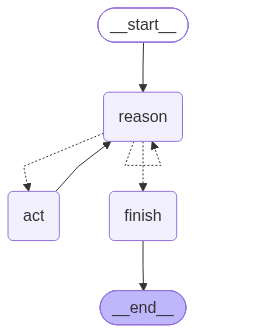

In [14]:
try:
    from IPython.display import Image, display
    display(Image(GRAPH.get_graph().draw_mermaid_png()))
except Exception as exc:  # needs internet (mermaid.ink); fall back to text
    print(GRAPH.get_graph().draw_mermaid())

In [15]:
# Default chosen from experiment E1 (best ReAct reliability). Override with AGENT_MODEL=provider:model in .env,
# e.g. AGENT_MODEL=groq:openai/gpt-oss-20b when Qwen's free daily quota is used up.
_provider, _, _model = os.getenv("AGENT_MODEL", "groq:qwen/qwen3.8-27b").partition(":")
DEFAULT_MODEL = {"provider": _provider, "model": _model}


def run_agent(question, persona="rami", history=None, model=None, config_override=None, variant=None, log=True):
    """Run one ReAct episode and return the final answer, trace and metrics."""
    cfg = {**(model or DEFAULT_MODEL), **PERSONAS[persona]["config"], **(config_override or {})}
    state = {
        "question": question, "history": history or [], "persona": persona, "cfg": cfg,
        "variant": {"cot": True, "few_shot": True, "placement": "system", "instructions": "full",
                    "budget_warning": False, **(variant or {})},  # off: E5b showed no benefit
        "scratchpad": "", "steps": [], "pending": None, "final_answer": None, "iterations": 0,
        "format_errors": 0, "llm_calls": 0, "latency_s": 0.0, "tokens_out": 0, "ignored_params": [],
        "native_tool_calls": 0, "implicit_finals": 0, "ungrounded_finals": 0,
    }
    try:
        final = GRAPH.invoke(state, {"recursion_limit": 4 * MAX_STEPS + 5})
        error = None
    except Exception as exc:  # provider outage etc.: report it instead of crashing the app
        final = {**state, "final_answer": "Sorry, the model is unavailable right now. Please try again in a minute."}
        error = f"{type(exc).__name__}: {str(exc)[:200]}"
    result = {
        "error": error,
        "question": question, "persona": persona, "cfg": cfg, "variant": final["variant"],
        "final_answer": final["final_answer"], "steps": final["steps"],
        "tools_used": [s["tool"] for s in final["steps"] if s["type"] == "action"],
        "format_errors": final["format_errors"], "llm_calls": final["llm_calls"],
        "latency_s": round(final["latency_s"], 2), "tokens_out": final["tokens_out"],
        "ignored_params": final["ignored_params"], "native_tool_calls": final["native_tool_calls"],
        "implicit_finals": final.get("implicit_finals", 0), "ungrounded_finals": final.get("ungrounded_finals", 0),
        "scratchpad": final["scratchpad"],
    }
    if log:
        with open(LOG_DIR / "runs.jsonl", "a", encoding="utf-8") as f:
            f.write(json.dumps({"time": datetime.now(timezone.utc).isoformat(timespec="seconds"), **result},
                               ensure_ascii=False, default=str) + "\n")
    return result


def format_trace(result):
    """Readable Thought / Action / Observation trace."""
    out = []
    for s in result["steps"]:
        if s.get("thought"):
            out.append(f"Thought: {s['thought']}")
        if s["type"] == "action":
            out.append(f"Action: {s['tool']}({json.dumps(s['args'], ensure_ascii=False)})")
            out.append(f"Observation: {json.dumps(s['observation'], ensure_ascii=False)[:400]}")
        elif s["type"] == "format_error":
            out.append(f"[format error] {s['error']}")
        else:
            out.append(f"Final Answer: {s['answer']}")
    return "\n".join(out)

## 9. Live demo: one task per persona
Uses `DEFAULT_MODEL`: Qwen3.8-27B via Groq, unless `AGENT_MODEL` is set in `.env`.

In [16]:
for persona, question in [("rami", "An easy day hike in the Shouf in October for two beginners?"),
                          ("hala", "We plan Sir ed-Danniyeh to Ehden in January with a fit group. Go or no-go?"),
                          ("nour", "What should I pack for 3 days on the trail in the north in August?")]:
    r = run_agent(question, persona=persona)
    print("=" * 90, f"\n{PERSONAS[persona]['name']} ({PERSONAS[persona]['title']}) | model: {r['cfg']['model']} | tools: {r['tools_used']} | "
          f"LLM calls: {r['llm_calls']} | format errors: {r['format_errors']}\n")
    print(format_trace(r))

Rami (Friendly Trail Buddy) | model: openai/gpt-oss-20b | tools: ['search_trail_sections', 'estimate_hike_time'] | LLM calls: 3 | format errors: 0

Action: search_trail_sections({"region": "shouf", "difficulty": "easy", "max_distance_km": 15, "month": "October"})
Observation: {"count": 1, "sections": [{"id": "S08", "name": "Falougha to Ain Zhalta", "region": "shouf", "difficulty": "easy", "distance_km": 11.0, "elevation_gain_m": 400, "highlights": "Pine woods descending to the Ain Zhalta cedar entrance"}]}
Action: estimate_hike_time({"distance_km": 11.0, "elevation_gain_m": 400, "fitness": "beginner"})
Observation: {"moving_hours": 3.7, "total_hours_with_breaks": 4.5, "fitness_factor": 1.3, "method": "Naismith's rule (5 km/h + 1 h per 600 m ascent), +20% for breaks"}
Final Answer: **Top pick:** Falougha to Ain Zhalta (S08) – a gentle cedar‑lined walk through pine woods, ending at a serene cedar grove.  
**Stats:** 11 km, +400 m, about 4.5 h for a beginner hiker.  
**Also consider:** No

## 10. Experiments
All runs are produced by `experiments.py` (resumable, one thread per model) and stored in `results/runs.jsonl`; an LLM judge
(Gemini, temperature 0) scores **persona fit** and **helpfulness** (1-5) in `results/judge.jsonl`.

**Automatic metrics per run:** `completed`, `format_ok` (final answer follows the persona's output format), `tool_recall`
(required tools actually used), `fact_score` (checkable facts from observations present, e.g. 4.5 h, S08, NO-GO), `quality`
(mean of those four), Hala's `verdict_correct`, plus format errors, ungrounded attempts, steps, latency.

| Exp | Question | Design | Model |
|---|---|---|---|
| E1 | Which model works best as the ReAct engine, per persona? | 3 personas x 2 tasks x 4 models | Gemini 3.5 flash-lite, Qwen3.8-27B, GPT-OSS-120B, GPT-OSS-20B |
| E2 | Does each persona's own config suit it best? | 6 tasks x 3 configs (each persona's) | GPT-OSS-120B |
| E3 | Prompt engineering: CoT, few-shot, placement | 2 x 2 x 2 variants x 3 tasks | GPT-OSS-20B |
| E4 | Single-parameter sweeps (3 repeats each) | temperature, top_p, penalties, max_tokens; top_k | Qwen3.8-27B; Gemini for top_k |
| E5 | Instructions ablation; last-step budget warning | full vs minimal instructions x 6 tasks; warning on/off x 2 tasks x 2 reps | Qwen3.8-27B (+ GPT-OSS-20B for E5b) |

In [17]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

runs = [json.loads(l) for l in open("results/runs.jsonl", encoding="utf-8") if l.strip()]
judge = {j["run_id"]: j for j in (json.loads(l) for l in open("results/judge.jsonl", encoding="utf-8") if l.strip())}
df = pd.DataFrame([{**{k: r[k] for k in ("run_id", "exp", "model_key", "case", "persona", "label", "rep", "final_answer")},
                    **r["metrics"], "format_errors": r["format_errors"], "ungrounded": r.get("ungrounded_finals", 0),
                    "native_calls": r.get("native_tool_calls", 0), "implicit": r.get("implicit_finals", 0),
                    "latency_s": r["latency_s"], "error": bool(r["error"]),
                    "persona_fit": judge.get(r["run_id"], {}).get("persona_fit"),
                    "helpfulness": judge.get(r["run_id"], {}).get("helpfulness")} for r in runs])
AGG = dict(quality=("quality", "mean"), facts=("fact_score", "mean"), format_ok=("format_ok", "mean"),
           tool_recall=("tool_recall", "mean"), format_errors=("format_errors", "mean"), ungrounded=("ungrounded", "mean"),
           persona_fit=("persona_fit", "mean"), helpfulness=("helpfulness", "mean"), words=("words", "mean"), n=("quality", "size"))
print(len(df), "runs |", df.error.sum(), "provider errors |", df.persona_fit.notna().sum(), "judged")

128 runs | 0 provider errors | 128 judged


### E1: persona x model

,quality,facts,format_ok,tool_recall,format_errors,ungrounded,persona_fit,helpfulness,words,n
model_key,,,,,,,,,,
qwen3.8-27b,0.88,0.83,0.83,1.00,0.00,0.00,3.67,4.00,110.00,6
gpt-oss-20b,0.78,0.72,0.83,0.75,0.00,0.00,3.50,3.83,68.17,6
gemini-3.5-flash-lite,0.53,0.39,0.67,0.42,1.33,0.00,3.17,3.67,81.33,6
gpt-oss-120b,0.33,0.06,0.50,0.08,1.67,0.17,3.00,3.33,65.50,6


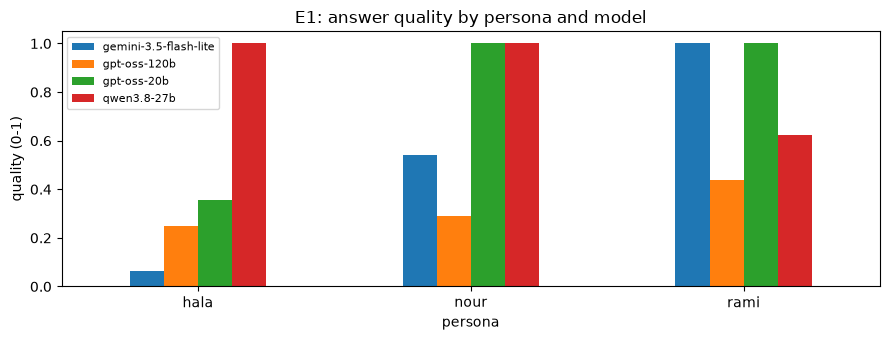

Hala verdict accuracy by model:
model_key
gemini-3.5-flash-lite    0.0
gpt-oss-120b             0.0
gpt-oss-20b              0.5
qwen3.8-27b              1.0
Name: verdict_correct, dtype: object


In [18]:
e1 = df[df.exp == "E1"]
display(e1.groupby("model_key").agg(**AGG).round(2).sort_values("quality", ascending=False))
pivot = e1.pivot_table(index="persona", columns="model_key", values="quality", aggfunc="mean")
ax = pivot.plot.bar(figsize=(9, 3.5), rot=0, title="E1: answer quality by persona and model")
ax.set_ylim(0, 1.05); ax.set_ylabel("quality (0-1)"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()
print("Hala verdict accuracy by model:")
print(e1[e1.persona == "hala"].groupby("model_key")["verdict_correct"].mean())

### E2: does each persona's own configuration suit it best?

quality  facts  format_ok  tool_recall  format_errors  \
persona label                                                             
hala    cfg_hala     0.38   0.50        0.5         0.00            2.0   
        cfg_nour     0.60   0.42        1.0         0.00            1.5   
        cfg_rami     0.31   0.25        0.5         0.00            2.5   
nour    cfg_hala     1.00   1.00        1.0         1.00            1.0   
        cfg_nour     0.58   0.33        1.0         0.00            0.0   
        cfg_rami     0.25   0.00        0.5         0.00            2.5   
rami    cfg_hala     0.44   0.50        0.5         0.25            2.5   
        cfg_nour     0.38   0.25        0.5         0.25            1.5   
        cfg_rami     0.19   0.00        0.0         0.25            2.5   

                  ungrounded  persona_fit  helpfulness  words  n  
persona label                                                     
hala    cfg_hala         0.0          1.5          1.5   36.0  2  
        cfg_nour         0.0          2.0          2.0   41.0  2  
        cfg_rami         0.5          3.0          3.0   33.5  2  
nour    cfg_hala         0.5          4.5          5.0  127.5  2  
        cfg_nour         0.0          4.5          4.5  135.5  2  
        cfg_rami         0.5          3.0          3.0   61.0  2  
rami    cfg_hala         0.5          1.5          2.0   43.0  2  
        cfg_nour         1.5          2.5          3.0   48.5  2  
        cfg_rami         1.0          1.5          2.0   38.5  2

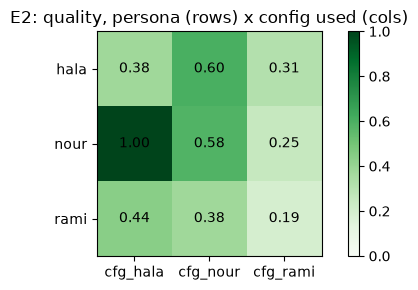

In [19]:
e2 = df[df.exp == "E2"]
heat = e2.pivot_table(index="persona", columns="label", values="quality", aggfunc="mean")
display(e2.groupby(["persona", "label"]).agg(**AGG).round(2))
fig, ax = plt.subplots(figsize=(5.5, 3))
im = ax.imshow(heat.values, cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(len(heat.columns)), heat.columns); ax.set_yticks(range(len(heat.index)), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.2f}", ha="center", va="center")
ax.set_title("E2: quality, persona (rows) x config used (cols)"); plt.colorbar(im); plt.tight_layout(); plt.show()

### E3: prompt engineering (CoT x few-shot x system vs in-message instructions)

,quality,facts,format_ok,tool_recall,format_errors,ungrounded,persona_fit,helpfulness,words,n
label,,,,,,,,,,
cot_few_system,0.86,0.78,1.00,0.67,0.00,0.0,4.33,4.00,68.67,3
nocot_few_system,0.86,0.78,1.00,0.67,0.00,0.0,3.33,3.33,73.00,3
nocot_zero_message,0.86,0.78,1.00,0.67,0.00,0.0,3.33,3.33,72.00,3
cot_zero_message,0.71,0.67,0.67,0.83,0.00,0.0,1.67,2.67,71.00,3
nocot_zero_system,0.58,0.33,0.67,0.67,0.33,0.0,2.33,3.00,67.67,3
cot_zero_system,0.50,0.33,0.33,0.67,0.00,0.0,2.00,2.00,66.67,3
cot_few_message,0.12,0.00,0.00,0.50,2.00,0.0,1.00,1.00,16.00,3
nocot_few_message,0.08,0.00,0.00,0.33,2.33,0.0,1.00,1.00,16.00,3


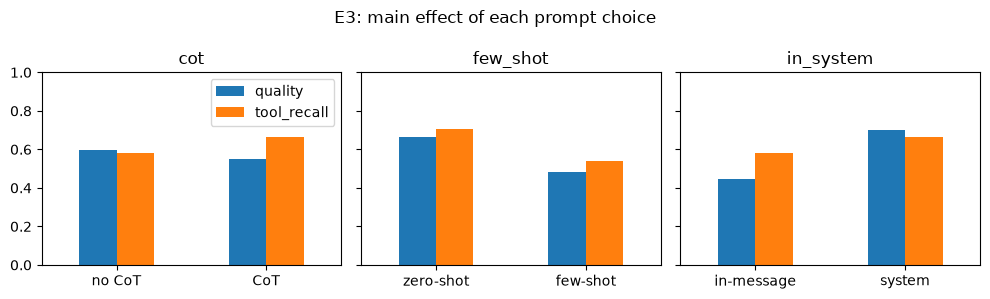

In [20]:
e3 = df[df.exp == "E3"].copy()
e3["cot"] = e3.label.str.startswith("cot"); e3["few_shot"] = e3.label.str.contains("_few_"); e3["in_system"] = e3.label.str.endswith("system")
display(e3.groupby("label").agg(**AGG).round(2).sort_values("quality", ascending=False))
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for ax, factor, names in zip(axes, ["cot", "few_shot", "in_system"], [("no CoT", "CoT"), ("zero-shot", "few-shot"), ("in-message", "system")]):
    vals = e3.groupby(factor)[["quality", "tool_recall"]].mean()
    vals.index = [names[int(i)] for i in vals.index]
    vals.plot.bar(ax=ax, rot=0, legend=ax is axes[0], ylim=(0, 1), title=factor)
plt.suptitle("E3: main effect of each prompt choice"); plt.tight_layout(); plt.show()

### E4: parameter sweeps (Rami's route task, 3 repeats each)

quality  facts  format_ok  tool_recall  \
model_key             label                                                    
gemini-3.5-flash-lite top_k_1            1.00    1.0       1.00         1.00   
                      top_k_400          0.96    1.0       1.00         0.83   
                      top_k_64           1.00    1.0       1.00         1.00   
qwen3.8-27b           frequency_1.5      0.92    1.0       0.67         1.00   
                      max_tokens_150     1.00    1.0       1.00         1.00   
                      presence_1.5       1.00    1.0       1.00         1.00   
                      temp_0.0           0.92    1.0       0.67         1.00   
                      temp_0.4           1.00    1.0       1.00         1.00   
                      temp_0.8           1.00    1.0       1.00         1.00   
                      temp_1.2           1.00    1.0       1.00         1.00   
                      temp_1.6           0.21    0.0       0.00         0.50   
                      top_p_0.3          1.00    1.0       1.00         1.00   

                                      format_errors  ungrounded  persona_fit  \
model_key             label                                                    
gemini-3.5-flash-lite top_k_1                  0.00         0.0         3.33   
                      top_k_400                0.00         0.0         3.67   
                      top_k_64                 0.67         0.0         3.33   
qwen3.8-27b           frequency_1.5            0.00         0.0         4.00   
                      max_tokens_150           0.00         0.0         3.00   
                      presence_1.5             0.00         0.0         4.00   
                      temp_0.0                 0.00         0.0         4.00   
                      temp_0.4                 0.00         0.0         3.00   
                      temp_0.8                 0.00         0.0         3.33   
                      temp_1.2                 0.00         0.0         4.67   
                      temp_1.6                 4.00         0.0         1.00   
                      top_p_0.3                0.00         0.0         4.33   

                                      helpfulness   words  n  diversity  
model_key             label                                              
gemini-3.5-flash-lite top_k_1                4.33   74.33  3       0.55  
                      top_k_400              4.00   79.00  3       0.57  
                      top_k_64               4.33   83.67  3       0.59  
qwen3.8-27b           frequency_1.5          4.67  112.33  3       0.68  
                      max_tokens_150         3.67   58.33  3       0.59  
                      presence_1.5           5.00  109.67  3       0.68  
                      temp_0.0               5.00  127.00  3       0.39  
                      temp_0.4               4.00  110.33  3       0.54  
                      temp_0.8               4.00  108.00  3       0.64  
                      temp_1.2               5.00  128.33  3       0.72  
                      temp_1.6               1.00  126.67  3       0.66  
                      top_p_0.3              5.00  122.33  3       0.29

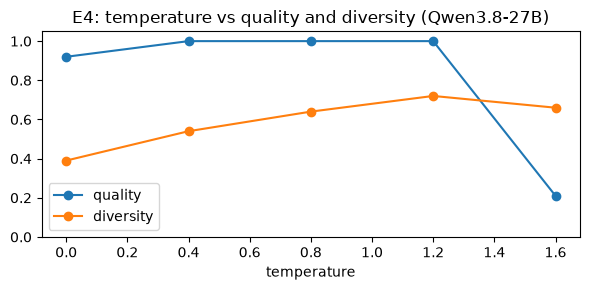

In [21]:
def diversity(answers):
    """Mean pairwise Jaccard distance between word sets: 0 = identical answers, 1 = nothing shared."""
    sets = [set(a.lower().split()) for a in answers]
    pairs = list(combinations(sets, 2))
    return round(sum(1 - len(a & b) / len(a | b) for a, b in pairs) / len(pairs), 2) if pairs else None

e4 = df[df.exp == "E4"]
table = e4.groupby(["model_key", "label"]).agg(**AGG).round(2)
table["diversity"] = e4.groupby(["model_key", "label"])["final_answer"].apply(lambda s: diversity(list(s)))
display(table)
temps = table.loc["qwen3.8-27b"].filter(like="temp_", axis=0)
temps.index = [float(i.split("_")[1]) for i in temps.index]
ax = temps[["quality", "diversity"]].sort_index().plot(marker="o", figsize=(6, 3), title="E4: temperature vs quality and diversity (Qwen3.8-27B)")
ax.set_xlabel("temperature"); ax.set_ylim(0, 1.05); plt.tight_layout(); plt.show()

In [22]:
# What does each setting actually produce? One answer per temperature.
for label in ["temp_0.0", "temp_0.8", "temp_1.6"]:
    print(f"--- {label} ---\n{e4[(e4.label == label)].iloc[0].final_answer[:500]}\n")

--- temp_0.0 ---
**Top pick:** Falougha to Ain Zhalta (S08) – a gentle 11 km stroll through golden pine woods that eases you down to the famous cedar entrance at Ain Zhalta.
**Stats:** 11 km, +400 m, about 4.5 h with breaks for a beginner hiker.
**Also consider:** If you'd like a shorter, even more relaxed option, ask me about the easy sections in Mount Lebanon for October and I'll point you to a 6–8 km alternative.
**Rami's tip:** October in the Shouf runs 10–24 °C with no snow, so pack a light fleece for the c

--- temp_0.8 ---
**Top pick:** Falougha to Ain Zhalta (S08) – a gentle 11 km walk through pine woods that eases you down to the ancient cedar entrance at Ain Zhalta, where the air smells of resin and the light filters gold through the canopy.
**Stats:** 11 km, +400 m, about 4.5 h (including breaks) for a beginner hiker.
**Also consider:** If you'd like a slower pace or want to add a café stop in a village along the way, break the walk into two halves – Falougha to the midpoint

### E5: does the instructions block matter, and does a last-step warning fix step-limit failures?
E1-E4 showed that the most common failure was **running out of steps** (repeated searches or repeated tool calls), so we tested a
one-line **budget warning** on the last step (E5b, on the tasks that failed in E1). E5a removes the dedicated instructions block
(keeping only the tool list and the action syntax). Two Qwen runs of E5b were skipped because Groq's free daily token quota
(200k tokens/day) ran out; that cell has n = 2 instead of 4.

In [23]:
e5 = df[df.exp == "E5"]
display(e5[e5.label.str.startswith("instr")].groupby("label").agg(**AGG).round(2))
display(e5[e5.label.str.startswith("instr")].pivot_table(index="case", columns="label", values="quality").round(2))
display(e5[e5.label.str.startswith("budget")].groupby(["model_key", "label"]).agg(**AGG).round(2))

,quality,facts,format_ok,tool_recall,format_errors,ungrounded,persona_fit,helpfulness,words,n
label,,,,,,,,,,
instr_full,0.88,0.83,0.83,1.00,0.0,0.0,3.17,3.83,101.50,6
instr_minimal,0.58,0.67,0.00,0.83,0.0,0.0,3.17,3.83,89.67,6


label,instr_full,instr_minimal
case,,
H1,1.00,0.12
H2,1.00,0.62
N1,1.00,0.75
N2,1.00,0.75
R1,1.00,0.75
R2,0.25,0.50


quality  facts  format_ok  tool_recall  format_errors  \
model_key   label                                                               
gpt-oss-20b budget_off     0.88   0.50        1.0         1.00            0.0   
            budget_on      0.56   0.50        0.5         0.75            0.5   
qwen3.8-27b budget_off     0.94   0.75        1.0         1.00            0.0   
            budget_on      1.00   1.00        1.0         1.00            0.5   

                        ungrounded  persona_fit  helpfulness   words  n  
model_key   label                                                        
gpt-oss-20b budget_off         0.0         2.00         2.00   37.25  4  
            budget_on          0.0         1.75         2.75   45.50  4  
qwen3.8-27b budget_off         0.0         3.25         4.50  133.00  4  
            budget_on          0.0         3.50         5.00   98.50  2

In [24]:
# Same question, with and without the instructions block (Hala, H1)
for label in ["instr_full", "instr_minimal"]:
    print(f"--- {label} ---\n{e5[(e5.label == label) & (e5.case == 'H1')].iloc[0].final_answer[:600]}\n")

--- instr_full ---
VERDICT: NO-GO
REASONS:
1. A danger-level safety alert is active for S03: the high plateau crossing is impassable when snow covers the trail (typically December to April).
2. January snow risk in the north region is high, and the section's max altitude is 2000 m, exceeding the 1500 m threshold.
3. The section's best months are June through September; January is outside the recommended window.
REQUIRED ACTIONS:
- Reschedule the hike to a month within the best-season window (June–September).
- If a winter attempt is non-negotiable, consult the ranger station for a snow-clearance confirmation and

--- instr_minimal ---
I couldn't complete this plan within my step limit. Please narrow the request (section, month, fitness).



## 11. Reflection
All numbers come from `results/runs.jsonl` (128 runs) and `results/judge.jsonl` (LLM judge, 1-5). "Quality" is the mean of
four automatic checks: completed, followed the output format, used the required tools, and stated the checkable facts from the observations.

### 1. Which persona gave the most helpful or natural results?
**Nour, the Gear Quartermaster.** Across all completed runs Nour had the best judge scores (persona fit **3.95**, helpfulness
**4.36**), and on the best model (Qwen3.8-27B) Nour scored 4.5 / 5.0 with perfect quality. Packing is a well-structured task:
one tool returns most of what is needed, and the persona's "one line per item, no vague advice" style matches what a hiker wants.
**Rami** was a close second on helpfulness (4.30) and had the highest automatic quality (0.91), but his persona fit varied with
temperature: the judge rated him 3.0-3.3 at temperature 0.4-0.8 and **4.67 at 1.2**, where his descriptions became more vivid.
**Hala** was the hardest persona (fit 3.33): a strict, rule-based verdict exposes every weakness of a model. Only Qwen got all of
her go / no-go verdicts right; Gemini, GPT-OSS-120B and GPT-OSS-20B were right 0-50% of the time.

### 2. Which prompt and configuration combination performed best?
**Qwen3.8-27B + the full instructions block in the system prompt (with the worked example and `Thought:` lines) + each persona's own
low-to-moderate temperature** (E1 quality 0.88, the only model with zero format errors and 100% correct verdicts). Supporting evidence:
* **Model choice mattered most** (E1): Qwen 0.88 > GPT-OSS-20B 0.78 > Gemini 3.5 flash-lite 0.53 > GPT-OSS-120B 0.33. The biggest
  model was the worst ReAct engine here, because it is trained for its own native tool-calling format and kept ignoring ours.
* **System-prompt instructions beat in-message instructions** (E3: 0.70 vs 0.44 quality, 0.08 vs 1.08 format errors per run).
* **Few-shot did not help GPT-OSS-20B** (E3: 0.48 vs 0.66). Combined with in-message placement it was the worst setting (0.08-0.12):
  the model copied the example's `Action:` lines into its native tool channel and ran out of steps.
* **Visible chain-of-thought made no measurable difference** on GPT-OSS-20B (0.55 vs 0.60), which already reasons on a hidden
  channel. We keep `Thought:` lines anyway because they make every trace explainable.
* **Temperature** (E4, Rami on Qwen): quality stayed at about 1.0 from 0.0 to 1.2 while answer diversity rose from 0.39 to 0.72
  and persona fit peaked at 1.2. At **1.6 the agent collapsed** (quality 0.21, 4 format errors per run, garbled text).
  **top_p 0.3** gave the least diverse answers (0.29) with full quality: a good fit for Hala. **Presence and frequency penalties
  of 1.5** kept quality and raised diversity (0.68) and helpfulness (4.7-5.0): useful for Rami and Nour. **max_tokens 150**
  still worked because each ReAct step is short, but answers shrank to 58 words and persona fit fell to 3.0.
* **top_k** (Gemini only) had no visible effect: even top_k = 1 was not deterministic (diversity 0.55), because Gemini's hidden
  thinking runs before sampling.
* **Persona configs on a weak model** (E2, GPT-OSS-120B, 2 runs per cell) were dominated by noise: low-temperature configs helped
  every persona slightly, so a reliable model matters more than fine-tuning sampling parameters.

### 3. How well did the agent reason and use tools?
With Qwen, very well: it searched, then estimated or checked safety, and cited the observed numbers (e.g. "max altitude 2000 m,
above the 1500 m threshold, January snow risk high, danger alert: NO-GO"). Tool recall was 100% in E1. Failure modes we observed:
* **Step-limit exhaustion** from repeated calls: Qwen searched 4 times before estimating on an open-ended request, and GPT-OSS-20B
  called `check_safety_alerts` four times in a row. A last-step "give the final answer now" warning (E5b) **did not fix this**,
  because the steps were already wasted in a loop. The right fix is loop detection (reject an identical repeated call), left as future work.
* **Hallucinated tools and observations**: GPT-OSS-120B called `repo_browser.open_file` (a tool from its training data), wrote
  "Observation: a danger alert..." without calling anything, and once invented sections "S22" and "S19". Our **grounding guard**
  (no final answer before any tool call) caught these, but at the step limit it still produced a wrong NO-GO for a safe section.
* **Format drift**: GPT-OSS often wrote a perfect answer without the `Final Answer:` prefix, or used its native tool channel.
  We accept both (implicit finals; native calls converted back to text Actions) and count them.

### 4. Did the instructions block change the agent's behaviour?
**Yes, strongly.** In E5a we replaced the dedicated block with a one-line minimum (tool list plus action syntax) on Qwen:
quality fell from **0.88 to 0.58**, format compliance from **83% to 0%**, and Hala's January safety check went from a perfect
NO-GO citing the alert, the altitude and the rule to running out of steps without any verdict. The block's specific parts
matched specific behaviours: the **decision rule** produced consistent verdicts, the **grounding rule** made the agent quote
observation numbers instead of guessing, and the **output formats** made answers easy to scan and to evaluate automatically.
The LLM judge rated tone and helpfulness about the same with and without the block (3.2 / 3.8 for both), which shows that the
block mainly buys **reliability and structure**, while tone comes from the persona.

### 5. Biggest implementation challenges
1. **Every provider bends the text-ReAct protocol differently.** GPT-OSS emitted native tool calls that Groq rejected
   ("Tool choice is none, but model called a tool"), or output Groq could not parse. Gemini 3.5 flash-lite returned empty
   `MALFORMED_RESPONSE` replies on multi-step prompts, counts hidden thinking tokens against `max_output_tokens`, and rejects
   presence / frequency penalties outright.
2. **Our own harness first under-reported the models.** The first experiment pass marked 56 runs as failures largely because the
   parser was too strict (answers without the `Final Answer:` prefix). We fixed the parser, added the grounding guard, and re-ran
   those runs; the originals are kept in `results/*_discarded_v1.jsonl` for transparency.
3. **Free-tier limits shaped the design**: 15 requests/min on Gemini, 8k tokens/min and 200k tokens/day per model on Groq. We
   ran one worker thread per model, made the runner resumable, and capped retry waits after a long `retry-after` stalled a run.
   Two E5b runs were skipped when Qwen's daily quota ran out.
4. **Measuring "good"**: we combined automatic checks (format, tools, facts, verdicts) with an LLM judge for tone and helpfulness.
   With 2-3 repeats per setting, small differences (for example in E2) are within noise; the large effects (model choice,
   instruction placement, the instructions block, temperature 1.6) are the robust findings.

## 12. Gradio app
Pick a persona and a model; the right panel shows the full ReAct trace for every reply.

In [25]:
MODEL_CHOICES = {
    "Qwen3.8 27B (Groq)": {"provider": "groq", "model": "qwen/qwen3.8-27b"},
    "Gemini 3.5 flash-lite (API)": {"provider": "gemini", "model": GEMINI_MODEL},
    "GPT-OSS 120B (Groq)": {"provider": "groq", "model": "openai/gpt-oss-120b"},
    "GPT-OSS 20B (Groq)": {"provider": "groq", "model": "openai/gpt-oss-20b"},
}


def build_ui():
    import gradio as gr

    persona_labels = {f"{p['name']} - {p['title']}": pid for pid, p in PERSONAS.items()}
    # Pre-select the configured default model (AGENT_MODEL) in the dropdown.
    default_label = next((k for k, v in MODEL_CHOICES.items() if v["model"] == DEFAULT_MODEL["model"]), list(MODEL_CHOICES)[0])

    def respond(message, history, persona_label, model_label):
        hist = [{"role": m["role"], "content": m["content"] if isinstance(m["content"], str)
                 else " ".join(c.get("text", "") for c in m["content"] if isinstance(c, dict))}
                for m in history if isinstance(m, dict)][-8:]
        result = run_agent(message, persona=persona_labels[persona_label], history=hist, model=MODEL_CHOICES[model_label])
        trace = (f"**Persona:** {persona_label}  \n**Tools:** {', '.join(result['tools_used']) or 'none'}  \n"
                 f"**LLM calls:** {result['llm_calls']} | **format errors:** {result['format_errors']} | "
                 f"**latency:** {result['latency_s']} s\n\n```text\n{format_trace(result)}\n```")
        return result["final_answer"], trace

    with gr.Blocks(title="Cedar Trails") as demo:
        gr.Markdown("# Cedar Trails\nA ReAct hiking planner for the Lebanon Mountain Trail. Pick a persona and ask away.")
        with gr.Row():
            persona = gr.Dropdown(list(persona_labels), value=list(persona_labels)[0], label="Persona")
            model = gr.Dropdown(list(MODEL_CHOICES), value=default_label, label="Model")
        with gr.Row():
            with gr.Column(scale=3):
                trace = gr.Markdown(render=False)
                gr.ChatInterface(respond, additional_inputs=[persona, model], additional_outputs=[trace],
                                 examples=[["An easy day hike in the Shouf in October for two beginners?", list(persona_labels)[0], default_label],
                                           ["We plan Sir ed-Danniyeh to Ehden in January with a fit group. Go or no-go?", list(persona_labels)[1], default_label],
                                           ["What should I pack for 3 days on the trail in the north in August?", list(persona_labels)[2], default_label]],
                                 cache_examples=False)
            with gr.Column(scale=2):
                gr.Markdown("### ReAct trace")
                trace.render()
    return demo

In [26]:
demo = build_ui()
demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
